# BERT の各層に品詞や構文の情報がどれくらい入っているかを調べる (プロービング)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/08_transformers/probing.ipynb)

NLP クックブック 08-19 ／ Transformers の基本操作

> GPU ランタイム推奨 (ランタイム → ランタイムのタイプを変更 → T4 GPU)

BERT の内部の単語ベクトルに、品詞や係り受けの情報がどの層でどれくらい表れているかを、簡単な分類器 (プローブ) で調べたい。

In [1]:
!pip install -q fugashi unidic-lite conllu

In [2]:
import random
import urllib.request
import numpy as np
import torch
from conllu import parse

random.seed(0); np.random.seed(0); torch.manual_seed(0)

# UD Japanese-GSD (CC BY-SA 4.0、https://github.com/UniversalDependencies/UD_Japanese-GSD)
base = "https://raw.githubusercontent.com/UniversalDependencies/UD_Japanese-GSD/master/ja_gsd-ud-"
def load(split, n=None):
    sents = parse(urllib.request.urlopen(base + split + ".conllu").read().decode("utf-8"))[:n]
    return [[t for t in s if isinstance(t["id"], int)] for s in sents]   # 複数語トークンなどの行を除く

train, test = load("train", 3000), load("test")   # 学習データは先頭 3000 文だけ使う
print(len(train), "文", sum(map(len, train)), "語 (学習) /", len(test), "文", sum(map(len, test)), "語 (評価)")
print([(t["form"], t["upos"], t["deprel"]) for t in test[0]])

3000 文 70320 語 (学習) / 543 文 13034 語 (評価)
[('これ', 'PRON', 'obl'), ('に', 'ADP', 'case'), ('不快', 'NOUN', 'compound'), ('感', 'NOUN', 'obj'), ('を', 'ADP', 'case'), ('示す', 'VERB', 'acl'), ('住民', 'NOUN', 'nsubj'), ('は', 'ADP', 'case'), ('い', 'VERB', 'advcl'), ('まし', 'AUX', 'aux'), ('た', 'AUX', 'aux'), ('が', 'SCONJ', 'mark'), (',', 'PUNCT', 'punct'), ('現在', 'ADV', 'advmod'), (',', 'PUNCT', 'punct'), ('表立っ', 'VERB', 'advcl'), ('て', 'SCONJ', 'mark'), ('反対', 'NOUN', 'nmod'), ('や', 'ADP', 'case'), ('抗議', 'NOUN', 'nmod'), ('の', 'ADP', 'case'), ('声', 'NOUN', 'obj'), ('を', 'ADP', 'case'), ('挙げ', 'VERB', 'acl'), ('て', 'SCONJ', 'mark'), ('いる', 'VERB', 'fixed'), ('住民', 'NOUN', 'nsubj'), ('は', 'ADP', 'case'), ('い', 'VERB', 'root'), ('ない', 'AUX', 'aux'), ('よう', 'AUX', 'aux'), ('です', 'AUX', 'aux'), ('。', 'PUNCT', 'punct')]


In [3]:
from transformers import AutoConfig, AutoModel, AutoTokenizer

device = "cuda" if torch.cuda.is_available() else "cpu"
name = "tohoku-nlp/bert-base-japanese-v3"   # Apache 2.0
tokenizer = AutoTokenizer.from_pretrained(name)

def encode(sent):
    """UD の語ごとにサブワードに分け、各語の先頭サブワードの位置を覚えておく"""
    ids, first = [tokenizer.cls_token_id], []
    for t in sent:
        first.append(len(ids))
        ids += tokenizer.encode(t["form"], add_special_tokens=False) or [tokenizer.unk_token_id]
    return ids + [tokenizer.sep_token_id], first

@torch.no_grad()
def features(model, sents, batch_size=32):
    """全層 (埋め込み層 + 12 層) の語ごとのベクトル: (13, 語数, 768)"""
    encoded = [encode(s) for s in sents]
    order = sorted(range(len(sents)), key=lambda i: len(encoded[i][0]))   # 長さの近い文をまとめてパディングを減らす
    out = [None] * len(sents)
    for b in range(0, len(order), batch_size):
        idx = order[b:b + batch_size]
        L = max(len(encoded[i][0]) for i in idx)
        ids = torch.zeros(len(idx), L, dtype=torch.long)
        mask = torch.zeros(len(idx), L, dtype=torch.long)
        for j, i in enumerate(idx):
            ids[j, :len(encoded[i][0])] = torch.tensor(encoded[i][0]); mask[j, :len(encoded[i][0])] = 1
        ids, mask = ids.to(device), mask.to(device)
        hs = torch.stack(model(input_ids=ids, attention_mask=mask, output_hidden_states=True).hidden_states)
        for j, i in enumerate(idx):
            out[i] = hs[:, j, encoded[i][1]].half()             # 先頭サブワードのベクトル。メモリ節約のため float16 で保存 (1 モデルの学習データ分で約 1.4GB)
    return torch.cat(out, dim=1)

print("最長の文:", max(len(encode(s)[0]) for s in train + test), "サブワード")
bert = AutoModel.from_pretrained(name).to(device).eval()   # 推論だけなので float32 のまま (T4 でも 1GB 未満)
torch.manual_seed(0)
random_bert = AutoModel.from_config(AutoConfig.from_pretrained(name)).to(device).eval()   # 同じ構造で重みがランダムな対照モデル
# GPU で 1〜2 分 (CPU だと 10 分以上かかる)
feats = {m: (features(model, train), features(model, test)) for m, model in [("BERT", bert), ("random BERT", random_bert)]}
print(feats["BERT"][0].shape, f"GPU メモリ {torch.cuda.max_memory_allocated() / 1e9:.1f} GB" if device == "cuda" else "")

最長の文: 151 サブワード
torch.Size([13, 70320, 768]) GPU メモリ 5.5 GB


In [4]:
from collections import Counter
import torch.nn.functional as F

y = {task: tuple([t[task] for s in d for t in s] for d in (train, test)) for task in ["upos", "deprel"]}

# 対照タスク (Hewitt & Liang, 2019): 単語の形 (type) ごとにランダムなラベルを 1 つ決め、どこに出てきても同じラベルにする。
# ラベルは正解の品詞の頻度分布から引く。文脈とは無関係なので、当たるとしたら分類器が単語を丸暗記したから
rng = np.random.default_rng(0)
tags, counts = np.unique(y["upos"][0], return_counts=True)
forms = sorted({t["form"] for s in train + test for t in s})
control_map = dict(zip(forms, rng.choice(tags, size=len(forms), p=counts / counts.sum())))
y["control"] = tuple([control_map[t["form"]] for s in d for t in s] for d in (train, test))

def probe(Xtr, ytr, Xte, yte, epochs=20, return_pred=False):
    """線形の分類器 (多クラスのロジスティック回帰) を学習し、評価データの正解率 (と予測) を返す"""
    classes = {c: i for i, c in enumerate(sorted(set(ytr)))}
    ytr = torch.tensor([classes[c] for c in ytr], device=device)
    yte = torch.tensor([classes.get(c, -1) for c in yte], device=device)   # 学習データにないラベルは必ず不正解
    mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-6                                # 標準化
    Xtr, Xte = (Xtr - mu) / sd, (Xte - mu) / sd
    torch.manual_seed(0)
    clf = torch.nn.Linear(Xtr.shape[1], len(classes)).to(device)
    opt = torch.optim.AdamW(clf.parameters(), lr=3e-3, weight_decay=0.01)
    for _ in range(epochs):
        for i in torch.randperm(len(Xtr), device=device).split(1024):
            loss = F.cross_entropy(clf(Xtr[i]), ytr[i])
            opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        pred = clf(Xte).argmax(-1)
    acc = (pred == yte).float().mean().item()
    return (acc, [list(classes)[i] for i in pred.tolist()]) if return_pred else acc

# 2 モデル × 3 タスク × 13 層 = 78 個の分類器。T4 で 3〜5 分
acc = {}
for m, (Ftr, Fte) in feats.items():
    for task in ["upos", "deprel", "control"]:
        acc[m, task] = [probe(Ftr[l].float(), y[task][0], Fte[l].float(), y[task][1]) for l in range(Ftr.shape[0])]
        print(f"{m:12} {task:8}", " ".join(f"{a:.3f}" for a in acc[m, task]))

# 参考: 文脈を見ずに「学習データでその単語に最も多く付いていたラベル」を答える (未知語は全体の最頻ラベル)
def by_form(task):
    c = {}
    for t_, lab in zip((t["form"] for s in train for t in s), y[task][0]):
        c.setdefault(t_, Counter())[lab] += 1
    default = Counter(y[task][0]).most_common(1)[0][0]
    pred = [c[t["form"]].most_common(1)[0][0] if t["form"] in c else default for s in test for t in s]
    return float(np.mean(np.array(pred) == np.array(y[task][1])))
baseline = {task: by_form(task) for task in ["upos", "deprel"]}
print("単語ごとの最頻ラベル:", {k: round(v, 3) for k, v in baseline.items()})

BERT         upos     0.883 0.960 0.968 0.969 0.971 0.971 0.968 0.964 0.963 0.961 0.957 0.954 0.950
BERT         deprel   0.643 0.846 0.873 0.876 0.877 0.882 0.881 0.878 0.874 0.870 0.865 0.859 0.849
BERT         control  0.790 0.764 0.745 0.723 0.716 0.704 0.690 0.680 0.667 0.661 0.660 0.653 0.650
random BERT  upos     0.802 0.800 0.798 0.797 0.795 0.793 0.791 0.791 0.785 0.786 0.782 0.782 0.777
random BERT  deprel   0.590 0.592 0.595 0.598 0.598 0.596 0.599 0.598 0.596 0.593 0.592 0.593 0.590
random BERT  control  0.788 0.785 0.782 0.778 0.773 0.768 0.765 0.761 0.759 0.756 0.750 0.748 0.745
単語ごとの最頻ラベル: {'upos': 0.875, 'deprel': 0.613}


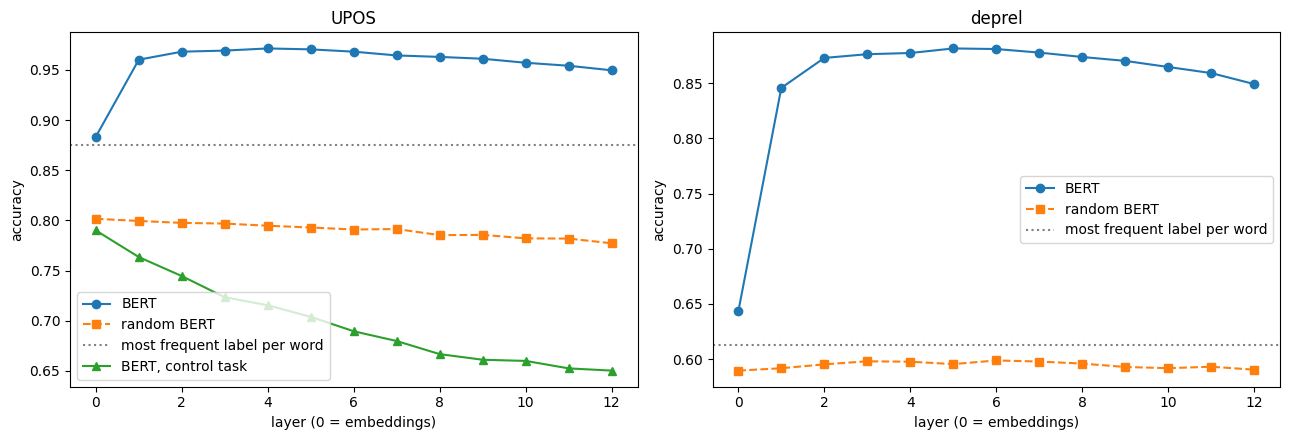

選択性 (BERT, UPOS): 0.093 0.197 0.224 0.246 0.256 0.267 0.279 0.285 0.296 0.300 0.297 0.302 0.299
選択性 (random BERT, UPOS): 0.014 0.014 0.016 0.019 0.022 0.025 0.026 0.031 0.027 0.030 0.032 0.034 0.032
upos: 最高は layer 4 (0.971)、layer 0 は 0.883
deprel: 最高は layer 5 (0.882)、layer 0 は 0.643


In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, task in zip(axes, ["upos", "deprel"]):
    ax.plot(acc["BERT", task], "o-", label="BERT")
    ax.plot(acc["random BERT", task], "s--", label="random BERT")
    ax.axhline(baseline[task], color="gray", ls=":", label="most frequent label per word")
    ax.set_title(task.upper() if task == "upos" else "deprel")
    ax.set_xlabel("layer (0 = embeddings)"); ax.set_ylabel("accuracy"); ax.legend()
axes[0].plot(acc["BERT", "control"], "^-", label="BERT, control task"); axes[0].legend()
plt.tight_layout(); plt.show()

# 選択性 (selectivity) = 本来のタスクの正解率 − 対照タスクの正解率
for m in ["BERT", "random BERT"]:
    sel = np.array(acc[m, "upos"]) - np.array(acc[m, "control"])
    print(f"選択性 ({m}, UPOS):", " ".join(f"{s:.3f}" for s in sel))
for task in ["upos", "deprel"]:
    best = int(np.argmax(acc["BERT", task]))
    print(f"{task}: 最高は layer {best} ({acc['BERT', task][best]:.3f})、layer 0 は {acc['BERT', task][0]:.3f}")

In [6]:
# 係り受けのラベルごとに、文脈のない層 0 と、評価データで最も良かった層を比べる
# (層の選択に評価データを使っているので、厳密には開発データ ja_gsd-ud-dev で選ぶ)
best = int(np.argmax(acc["BERT", "deprel"]))
Ftr, Fte = feats["BERT"]
gold = np.array(y["deprel"][1])
_, pred0 = probe(Ftr[0].float(), y["deprel"][0], Fte[0].float(), y["deprel"][1], return_pred=True)
_, predb = probe(Ftr[best].float(), y["deprel"][0], Fte[best].float(), y["deprel"][1], return_pred=True)
print(f"評価データで最も良かった層: {best}")
print(f"{'label':12}{'件数':>6}{'layer 0':>9}{f'layer {best}':>9}")
for lab, n in Counter(gold).most_common(12):
    m = gold == lab
    print(f"{lab:12}{n:6}{np.mean(np.array(pred0)[m] == lab):9.3f}{np.mean(np.array(predb)[m] == lab):9.3f}")

評価データで最も良かった層: 5
label           件数  layer 0  layer 5
case          2774    0.993    0.983
compound      1507    0.656    0.879
punct         1291    1.000    0.998
aux           1196    0.906    0.968
obl            884    0.313    0.723
mark           713    0.600    0.954
nmod           710    0.239    0.761
fixed          603    0.547    0.934
advcl          579    0.263    0.632
nsubj          558    0.161    0.857
root           543    0.311    0.867
acl            513    0.339    0.733


- プローブ (probe) は、モデルの内部表現を入力にした簡単な分類器で、その情報が表現から取り出せるかを調べる (線形のプローブは Alain & Bengio, 2016。BERT の層ごとの分析は Tenney et al., 2019 など)。単語ベクトルの取り出し方はこの章の「BERT から文脈に応じた単語ベクトルを取り出す」と同じく `output_hidden_states=True` で、層 0 は文脈を見ない埋め込み層の出力 (位置の情報は含む)。
- この実行では、品詞 (UPOS) は層 0 で 0.883 (単語ごとの最頻ラベルの 0.875 とほぼ同じ) から層 1 で 0.960 に上がり、層 4〜5 の 0.971 が最高で、層 12 では 0.950 に下がった。係り受けのラベル (deprel) は層 0 の 0.643 から層 5 の 0.882 まで上がった。評価は 543 文 (約 1.3 万語)、シード 1 つの結果なので、層 2〜6 の間の 0.01 未満の差で順位は決めない。
- 層 0 と、評価データで最も良かった層 5 のラベルごとの比較では、`nsubj` (0.161 → 0.857) や `nmod` (0.239 → 0.761) など、同じ名詞でも後ろの助詞や係り先によって決まるラベルが大きく上がった。`case` や `punct` は層 0 で既にほぼ当たる。日本語の品詞は単語の形でほぼ決まるので、文脈の効果は係り受けのラベルのほうが見えやすい。
- 対照タスク (Hewitt & Liang, 2019) の正解率は層 0 の 0.790 から層 12 の 0.650 まで下がり、選択性 (品詞の正解率 − 対照タスクの正解率) は 0.093 から約 0.30 に上がった。下の層ほど単語の丸暗記で当てやすい。ただし重みがランダムな BERT でも対照タスクは 0.788 から 0.745 に下がるので、低下の一部は学習の効果ではなく、層を重ねるごとにほかのトークンの情報が混ざることによる。正解率の最高 (層 4〜5) と選択性の最高 (層 9〜12、0.30 前後) の層がずれた点は、論文の ELMo の結果 (1 層目のほうが品詞の正解率はわずかに高いが、2 層目のほうが選択性はかなり高い) と似ている。
- 重みがランダムな BERT でも品詞は 0.78〜0.80 当たるが、対照タスクも 0.75〜0.79 当たり、選択性は 0.01〜0.03 程度しかない。単語の区別が残っていれば分類器が暗記で当てられるということで、「正解率が高い = モデルが品詞を学習した」とは言えない。必ず対照と比べる。
- プロービングで分かるのは「情報が (線形に) 取り出せる」ことまでで、モデルが予測にその情報を使っているかは分からない。分類器の表現力を上げれば正解率は上がるが、暗記できる分も増えるので選択性と合わせて見る。結果は学習データの量、分類器の設定、サブワードの代表の選び方 (ここでは先頭) にも左右される。この章の「アテンションの重みをヒートマップで可視化する」の重みと同様、相関的な分析であることに注意。
- データは構文解析の章と同じ UD Japanese-GSD (CC BY-SA 4.0。元の文は Google UDT 2.0 のニュース・ブログ)、モデルは東北大学の BERT (Apache 2.0、CC-100 と Wikipedia で学習)。UD の単語単位 (短単位) をそのまま 1 語ずつトークナイザに通しているので、モデル本来の分割 (MeCab + unidic-lite) とは少し違う入力になる。